Exercise 2 — Multinomial Naïve Bayes on Text Data
Problem title: Classifying incoming IT support messages by service category

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

data = {
    'ID': [
        'M01', 'M02', 'M03', 'M04', 'M05',
        'M06', 'M07', 'M08', 'M09', 'M10',
        'M11', 'M12', 'M13', 'M14', 'M15'
    ],

    'Message': [
        'wifi is not connecting in the hostel',
        'internet connection is very slow',
        'router is not working and wifi is down',
        'unable to access campus network',
        'wifi disconnects during online classes',

        'reset my password for student account',
        'cannot login to my email account',
        'account is locked after wrong password',
        'please activate my student login',
        'forgot password and cannot sign in',

        'laptop screen is not turning on',
        'keyboard keys are damaged',
        'computer is making a loud fan noise',
        'printer is not working in the lab',
        'laptop battery is not charging'
    ],

    'Category': [
        'Network', 'Network', 'Network', 'Network', 'Network',
        'Account', 'Account', 'Account', 'Account', 'Account',
        'Hardware', 'Hardware', 'Hardware', 'Hardware', 'Hardware'
    ]
}

df = pd.DataFrame(data)

print("Helpdesk Dataset:")
display(df)


Helpdesk Dataset:


,ID,Message,Category
0,M01,wifi is not connecting in the hostel,Network
1,M02,internet connection is very slow,Network
2,M03,router is not working and wifi is down,Network
3,M04,unable to access campus network,Network
4,M05,wifi disconnects during online classes,Network
5,M06,reset my password for student account,Account
6,M07,cannot login to my email account,Account
7,M08,account is locked after wrong password,Account
8,M09,please activate my student login,Account
9,M10,forgot password and cannot sign in,Account


Dataset inspection

In [3]:

print("First five records:")
display(df.head())

print("Dataset dimensions:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nClass distribution:")
print(df['Category'].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())


First five records:


,ID,Message,Category
0,M01,wifi is not connecting in the hostel,Network
1,M02,internet connection is very slow,Network
2,M03,router is not working and wifi is down,Network
3,M04,unable to access campus network,Network
4,M05,wifi disconnects during online classes,Network


Dataset dimensions: (15, 3)

Data types:
ID          object
Message     object
Category    object
dtype: object

Class distribution:
Category
Network     5
Account     5
Hardware    5
Name: count, dtype: int64

Missing values:
ID          0
Message     0
Category    0
dtype: int64

Duplicate records: 0


 Convert all messages to lowercase and remove leading/trailing whitespace.

In [4]:

# Text preprocessing

df['Message'] = df['Message'].str.lower().str.strip()

print("Preprocessed messages:")
display(df[['ID', 'Message', 'Category']])


Preprocessed messages:


,ID,Message,Category
0,M01,wifi is not connecting in the hostel,Network
1,M02,internet connection is very slow,Network
2,M03,router is not working and wifi is down,Network
3,M04,unable to access campus network,Network
4,M05,wifi disconnects during online classes,Network
5,M06,reset my password for student account,Account
6,M07,cannot login to my email account,Account
7,M08,account is locked after wrong password,Account
8,M09,please activate my student login,Account
9,M10,forgot password and cannot sign in,Account


Split the dataset into training and testing

In [5]:

# Separate input messages and target categories

X = df['Message']
y = df['Category']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.33,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training data shape: (10,)
Testing data shape: (5,)

Training class distribution:
Category
Account     4
Hardware    3
Network     3
Name: count, dtype: int64

Testing class distribution:
Category
Network     2
Hardware    2
Account     1
Name: count, dtype: int64


In [6]:

# Create CountVectorizer

vectorizer = CountVectorizer()

# Fit only on training messages
X_train_vector = vectorizer.fit_transform(X_train)

# Transform testing messages using the same vocabulary
X_test_vector = vectorizer.transform(X_test)

print("Training matrix shape:", X_train_vector.shape)
print("Testing matrix shape:", X_test_vector.shape)


Training matrix shape: (10, 42)
Testing matrix shape: (5, 42)


In [7]:

# Display vocabulary

print("Vocabulary:")
print(vectorizer.vocabulary_)


Vocabulary:
{'reset': 32, 'my': 25, 'password': 29, 'for': 13, 'student': 34, 'account': 1, 'computer': 7, 'is': 17, 'making': 24, 'loud': 23, 'fan': 12, 'noise': 27, 'unable': 37, 'to': 36, 'access': 0, 'campus': 5, 'network': 26, 'cannot': 6, 'login': 22, 'email': 11, 'wifi': 39, 'not': 28, 'connecting': 8, 'in': 15, 'the': 35, 'hostel': 14, 'keyboard': 18, 'keys': 19, 'are': 4, 'damaged': 10, 'please': 30, 'activate': 2, 'locked': 21, 'after': 3, 'wrong': 41, 'printer': 31, 'working': 40, 'lab': 20, 'internet': 16, 'connection': 9, 'very': 38, 'slow': 33}


In [8]:

# Convert training matrix into a DataFrame

dtm = pd.DataFrame(
    X_train_vector.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=X_train.index
)

print("Document-Term Matrix (First 5 messages):")
display(dtm.head())


Document-Term Matrix (First 5 messages):


,access,account,activate,after,are,campus,cannot,computer,connecting,connection,...,reset,slow,student,the,to,unable,very,wifi,working,wrong
5,0,1,0,0,0,0,0,0,0,0,...,1,0,1,0,0,0,0,0,0,0
12,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0
6,0,1,0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0
0,0,0,0,0,0,0,0,0,1,0,...,0,0,0,1,0,0,0,1,0,0


Train Multinomial Naive Bayes

In [9]:

# Create Multinomial Naive Bayes model

model = MultinomialNB()

# Train the model
model.fit(X_train_vector, y_train)

print("Multinomial Naive Bayes model trained successfully!")


Multinomial Naive Bayes model trained successfully!


In [10]:

print("Classes:")
print(model.classes_)

print("\nClass Priors:")
display(pd.Series(
    model.class_log_prior_,
    index=model.classes_
).apply(np.exp))


Classes:
['Account' 'Hardware' 'Network']

Class Priors:


,0
Account,0.4
Hardware,0.3
Network,0.3


In [11]:

# Convert log probabilities into probabilities

word_probabilities = np.exp(model.feature_log_prob_)

word_probability_df = pd.DataFrame(
    word_probabilities,
    index=model.classes_,
    columns=vectorizer.get_feature_names_out()
)

print("Word probabilities for each category:")

for category in model.classes_:
    print(f"\nCategory: {category}")

    display(
        word_probability_df.loc[category]
        .sort_values(ascending=False)
        .head(10)
    )


Word probabilities for each category:

Category: Account


,Account
account,0.061538
my,0.061538
password,0.046154
student,0.046154
login,0.046154
is,0.030769
cannot,0.030769
after,0.030769
locked,0.030769
activate,0.030769



Category: Hardware


,Hardware
is,0.050847
computer,0.033898
keyboard,0.033898
keys,0.033898
lab,0.033898
loud,0.033898
fan,0.033898
in,0.033898
damaged,0.033898
are,0.033898



Category: Network


,Network
is,0.050847
access,0.033898
connecting,0.033898
connection,0.033898
slow,0.033898
wifi,0.033898
in,0.033898
hostel,0.033898
internet,0.033898
campus,0.033898


In [12]:

# Compare different smoothing values

model_default = MultinomialNB(alpha=1.0)
model_smooth = MultinomialNB(alpha=0.5)

model_default.fit(X_train_vector, y_train)
model_smooth.fit(X_train_vector, y_train)

print("Default alpha:", model_default.alpha)
print("Modified alpha:", model_smooth.alpha)

print("\nModel trained with alpha = 1.0 and alpha = 0.5")


Default alpha: 1.0
Modified alpha: 0.5

Model trained with alpha = 1.0 and alpha = 0.5


Laplace smoothing is used to avoid zero probabilities for words that are not observed in a particular class during training. Alpha = 1.0 applies standard smoothing, whereas alpha = 0.5 applies less smoothing. Changing alpha can affect the calculated word probabilities and classification results.

In [13]:

# Create unseen messages

new_messages = pd.DataFrame({
    'Message': [
        'wifi is slow in the lab',
        'please reset my email password',
        'laptop battery is not charging',
        'cannot connect to the campus wifi',
        'my account is locked and I forgot password'
    ]
}, index=['Q01', 'Q02', 'Q03', 'Q04', 'Q05'])

# Apply the same fitted vectorizer
new_vectors = vectorizer.transform(new_messages['Message'])

# Predict categories
predictions = model.predict(new_vectors)

# Calculate posterior probabilities
probabilities = model.predict_proba(new_vectors)

# Display results
prediction_results = pd.DataFrame(
    probabilities,
    columns=[f'P({c})' for c in model.classes_],
    index=new_messages.index
)

prediction_results.insert(0, 'Message', new_messages['Message'])
prediction_results.insert(1, 'Predicted Category', predictions)

display(prediction_results)


,Message,Predicted Category,P(Account),P(Hardware),P(Network)
Q01,wifi is slow in the lab,Network,0.020294,0.326569,0.653137
Q02,please reset my email password,Account,0.975268,0.012366,0.012366
Q03,laptop battery is not charging,Hardware,0.154756,0.422622,0.422622
Q04,cannot connect to the campus wifi,Network,0.154381,0.093958,0.751661
Q05,my account is locked and I forgot password,Account,0.963356,0.018322,0.018322


Evaluate the model

In [14]:

# Predict testing messages

y_pred = model.predict(X_test_vector)

# Calculate metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average='weighted', zero_division=0
)

recall = recall_score(
    y_test, y_pred, average='weighted', zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average='weighted', zero_division=0
)

print("MODEL EVALUATION")
print("-------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


MODEL EVALUATION
-------------------------
Accuracy : 0.8
Precision: 0.8666666666666666
Recall   : 0.8
F1 Score : 0.7866666666666667

Classification Report:
              precision    recall  f1-score   support

     Account       1.00      1.00      1.00         1
    Hardware       0.67      1.00      0.80         2
     Network       1.00      0.50      0.67         2

    accuracy                           0.80         5
   macro avg       0.89      0.83      0.82         5
weighted avg       0.87      0.80      0.79         5



Confusion Matrix

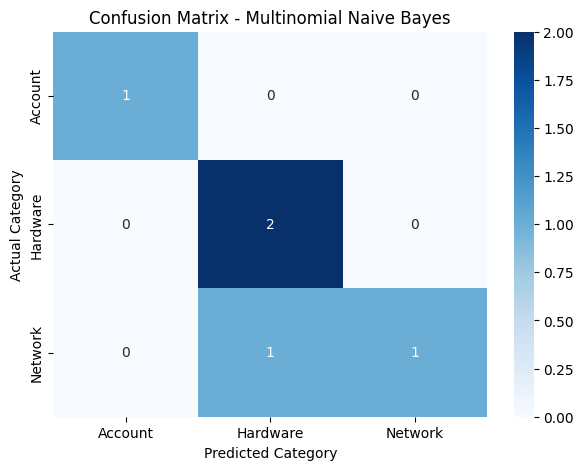

In [15]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.show()


In [16]:

additional_messages = [
    'wifi connection is not working',
    'my laptop camera is broken xyzdevice'
]

additional_vectors = vectorizer.transform(additional_messages)

additional_predictions = model.predict(additional_vectors)

additional_probabilities = model.predict_proba(additional_vectors)

additional_results = pd.DataFrame(
    additional_probabilities,
    columns=[f'P({c})' for c in model.classes_]
)

additional_results.insert(0, 'Message', additional_messages)
additional_results.insert(1, 'Predicted Category', additional_predictions)

display(additional_results)

# Check unknown word handling
print("Is 'xyzdevice' in vocabulary?",
      'xyzdevice' in vectorizer.vocabulary_)


,Message,Predicted Category,P(Account),P(Hardware),P(Network)
0,wifi connection is not working,Network,0.043649,0.318784,0.637567
1,my laptop camera is broken xyzdevice,Account,0.594274,0.202863,0.202863


Is 'xyzdevice' in vocabulary? False


Conclusion: The model was trained using a training dataset and evaluated using a separate testing dataset. It achieved 80% accuracy, 86.67% weighted precision, 80% weighted recall and 78.67% weighted F1-score. The model successfully predicted the categories of five unseen messages and was also tested with two additional messages, including one containing an unknown word. The results demonstrate that Multinomial Naïve Bayes can be used as a preliminary helpdesk message classification system. However, collecting more labelled data, improving text preprocessing, handling spelling variations and introducing human review are necessary before real-world deployment.